In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
df = pd.read_csv("1_He_2020_RMP_v2_with_sampling_criteria.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset shape: (19145, 15)

Columns:
['Unnamed: 0', 'id', 'index', 'department', 'teacher_name', 'rating', 'review_text', 'source', 'type', 'token_list', 'num_token', 'rating_bin', 'rating_cat', 'length_bin', 'sample_criteria']


,Unnamed: 0,id,index,department,teacher_name,rating,review_text,source,type,token_list,num_token,rating_bin,rating_cat,length_bin,sample_criteria
0,0,1_90_2430_1,0,English As A Second Language,Steven Cunningham,1.0,"Never trust yourself, you would be surprised b...",data1_19145,teacher review,"['Never', 'trust', 'yourself', ',', 'you', 'wo...",27,"(0.999, 2.5]",Neg,"(21.0, 41.0]","Neg_(21.0, 41.0]"
1,1,1_236_180_2,1,Spanish,Armando Valdes,1.0,"This class is an easy A, but don\'t expect to ...",data1_19145,teacher review,"['This', 'class', 'is', 'an', 'easy', 'A', ','...",75,"(0.999, 2.5]",Neg,"(61.0, 81.0]","Neg_(61.0, 81.0]"
2,2,1_182_1691_3,2,Music,Marcos Krieger,1.0,Overall terrible experience.,data1_19145,teacher review,"['Overall', 'terrible', 'experience', '.']",4,"(0.999, 2.5]",Neg,"(0.999, 21.0]","Neg_(0.999, 21.0]"
3,3,1_40_401_4,3,Business,Charles Hurt,1.0,He did not teach me a single thing. I went int...,data1_19145,teacher review,"['He', 'did', 'not', 'teach', 'me', 'a', 'sing...",73,"(0.999, 2.5]",Neg,"(61.0, 81.0]","Neg_(61.0, 81.0]"
4,4,1_37_1575_5,4,Biology,Leonardo Kurachi Ube,1.0,Not a bad professor as he is very passionate a...,data1_19145,teacher review,"['Not', 'a', 'bad', 'professor', 'as', 'he', '...",66,"(0.999, 2.5]",Neg,"(61.0, 81.0]","Neg_(61.0, 81.0]"


In [3]:
data = df[["review_text", "rating_cat"]].copy()

data.head()

,review_text,rating_cat
0,"Never trust yourself, you would be surprised b...",Neg
1,"This class is an easy A, but don\'t expect to ...",Neg
2,Overall terrible experience.,Neg
3,He did not teach me a single thing. I went int...,Neg
4,Not a bad professor as he is very passionate a...,Neg


In [4]:
print("Missing values:")
print(data.isnull().sum())

print("\nDuplicate rows:", data.duplicated().sum())
print("Duplicate reviews:", data["review_text"].duplicated().sum())

Missing values:
review_text    0
rating_cat     0
dtype: int64

Duplicate rows: 56
Duplicate reviews: 66


In [5]:
data = data.dropna(subset=["review_text", "rating_cat"])

data = data.drop_duplicates(subset=["review_text"])

data = data.reset_index(drop=True)

print("Dataset after cleaning:", data.shape)

Dataset after cleaning: (19079, 2)


In [6]:
print(data["rating_cat"].value_counts())

print("\nPercentage distribution:")
print(data["rating_cat"].value_counts(normalize=True) * 100)

rating_cat
Pos         9920
Neg         4737
Conf/Neu    4422
Name: count, dtype: int64

Percentage distribution:
rating_cat
Pos         51.994339
Neg         24.828345
Conf/Neu    23.177315
Name: proportion, dtype: float64


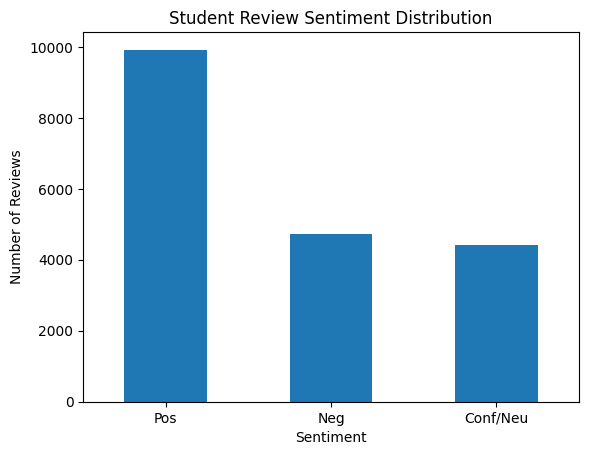

In [7]:
data["rating_cat"].value_counts().plot(kind="bar")

plt.title("Student Review Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.show()

In [8]:
def clean_text(text):
    text = str(text)
    
    # Convert to lowercase
    text = text.lower()
    
    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)
    
    # Remove HTML tags
    text = re.sub(r"<.*?>", "", text)
    
    # Keep alphabetic characters and spaces
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    
    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()
    
    return text


data["clean_text"] = data["review_text"].apply(clean_text)

data[["review_text", "clean_text"]].head()

,review_text,clean_text
0,"Never trust yourself, you would be surprised b...",never trust yourself you would be surprised by...
1,"This class is an easy A, but don\'t expect to ...",this class is an easy a but don t expect to le...
2,Overall terrible experience.,overall terrible experience
3,He did not teach me a single thing. I went int...,he did not teach me a single thing i went into...
4,Not a bad professor as he is very passionate a...,not a bad professor as he is very passionate a...


In [9]:
data = data[data["clean_text"].str.len() > 0]

data = data.reset_index(drop=True)

print("Final dataset size:", len(data))

Final dataset size: 19075


In [14]:
data = data[data["rating_cat"].isin(["Neg", "Pos"])].copy()
data["label"] = data["rating_cat"].map({
    "Neg": 0,
    "Pos": 1
})
data = data.dropna(subset=["label"]).reset_index(drop=True)

print(data["label"].value_counts())

label
1    9917
0    4736
Name: count, dtype: int64


In [15]:
X = data["clean_text"]
y = data["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 11722
Testing samples: 2931


In [16]:
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (11722, 10000)
Testing TF-IDF shape: (2931, 10000)


In [17]:
baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

baseline_model.fit(X_train_tfidf, y_train)

print("Baseline model trained successfully.")

Baseline model trained successfully.


In [18]:
y_pred = baseline_model.predict(X_test_tfidf)

print("Predictions generated:", len(y_pred))

Predictions generated: 2931


In [19]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

f1 = f1_score(y_test, y_pred)

print("Baseline Evaluation")
print("-------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

Baseline Evaluation
-------------------
Accuracy : 0.9219
Precision: 0.9217
Recall   : 0.9667
F1-score : 0.9437


In [20]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Negative", "Positive"]
    )
)

              precision    recall  f1-score   support

    Negative       0.92      0.83      0.87       947
    Positive       0.92      0.97      0.94      1984

    accuracy                           0.92      2931
   macro avg       0.92      0.90      0.91      2931
weighted avg       0.92      0.92      0.92      2931



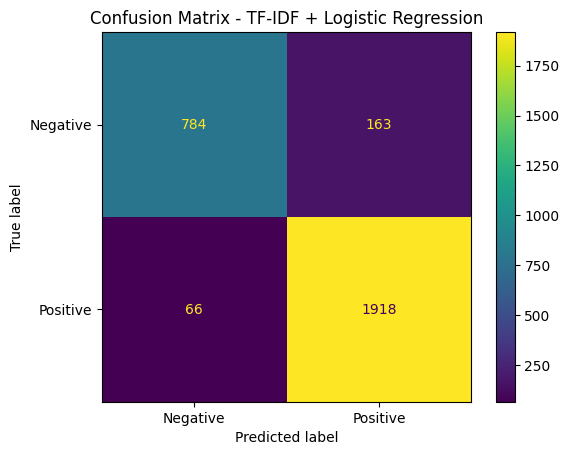

In [21]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot()

plt.title("Confusion Matrix - TF-IDF + Logistic Regression")
plt.show()

In [22]:
sample_reviews = [
    "The lectures were very informative and the professor explained everything clearly.",
    "The course was extremely difficult and the assignments were too much.",
    "The professor was knowledgeable and helpful.",
    "The lectures were boring and the teaching was not clear.",
    "The examples were excellent and helped me understand the concepts."
]

sample_clean = [clean_text(x) for x in sample_reviews]

sample_tfidf = tfidf.transform(sample_clean)

predictions = baseline_model.predict(sample_tfidf)

for review, prediction in zip(sample_reviews, predictions):
    sentiment = "Positive" if prediction == 1 else "Negative"
    
    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print()

Review: The lectures were very informative and the professor explained everything clearly.
Predicted sentiment: Positive

Review: The course was extremely difficult and the assignments were too much.
Predicted sentiment: Negative

Review: The professor was knowledgeable and helpful.
Predicted sentiment: Positive

Review: The lectures were boring and the teaching was not clear.
Predicted sentiment: Negative

Review: The examples were excellent and helped me understand the concepts.
Predicted sentiment: Positive



In [23]:
feature_names = np.array(tfidf.get_feature_names_out())

coefficients = baseline_model.coef_[0]

top_positive = feature_names[np.argsort(coefficients)[-20:]]
top_negative = feature_names[np.argsort(coefficients)[:20]]

print("Top Positive Features:")
print(top_positive)

print("\nTop Negative Features:")
print(top_negative)

Top Positive Features:
['highly' 'always' 'great teacher' 'funny' 'is great' 'dr' 'very helpful'
 'excellent' 'loved' 'love' 'interesting' 'professor' 'the best' 'fun'
 'easy' 'helpful' 'amazing' 'awesome' 'best' 'great']

Top Negative Features:
['not' 'worst' 'doesn' 'avoid' 'horrible' 'confusing' 'terrible' 'rude'
 'not take' 'unclear' 'not very' 'never' 'the worst' 'boring' 'do not'
 'nothing' 'not recommend' 'useless' 'no' 'when']


In [24]:
data.to_csv(
    "student_feedback_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


In [25]:
import joblib

joblib.dump(baseline_model, "baseline_sentiment_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and TF-IDF vectorizer saved.")

Model and TF-IDF vectorizer saved.
